# A real RPO event from public data: Cosmos 2612 and ICEYE-X36

In mid-October 2026, the Russian satellite Cosmos 2612 maneuvered to within roughly 2 to 3 km of ICEYE-X36, a commercial synthetic aperture radar satellite operated by the Finnish company ICEYE that supplies imagery used in support of Ukraine, coming as close as about 500 m at times between 16 and 19 October. The behaviour was tracked and reported publicly by LeoLabs and covered by, among others, [Ars Technica](https://arstechnica.com/space/2026/10/russian-spacecraft-maneuvers-in-extreme-proximity-to-satellite-used-by-ukraine/), [SpaceNews/Via Satellite](https://www.satellitetoday.com/government-military/2026/10/19/russian-satellite-maneuvered-within-extreme-proximity-of-iceye-satellite-leolabs-reports/), and [The War Zone](https://www.twz.com/news-features/russias-satellite-unprecedented-shadowing-of-a-very-particular-radar-imaging-satellite-is-a-big-deal).

This notebook asks a narrow, concrete question: starting from nothing but public two-line element sets (TLEs), the same kind of data available to anyone, can this project's existing relative-motion tools reconstruct the geometry of that encounter, the same way they already characterize the missions this project designs itself? The first step is just getting real-world data into the pipeline and checking it against a number that was actually reported, before trying anything more ambitious.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from sgp4.api import Satrec, jday

from ios_mission_planner.dynamics.relative.lvlh import inertial_to_lvlh
from ios_mission_planner.dynamics.relative.relative_orbit import relative_orbit_from_state

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"

## The data

Two-line elements for both objects, fetched from [CelesTrak](https://celestrak.org) on 2026-10-22 (NORAD catalog numbers 68762 for Cosmos 2612 and 59103 for ICEYE-X36). TLEs are mean orbital elements fitted to recent tracking data, not an exact instantaneous state, and this project has no way to pull a historical archive for free without a Space-Track account, so these are the most recent elements available, not elements from the actual close-approach window of 15 to 19 October. That gap matters and is addressed directly below, not glossed over.

In [2]:
tle_cosmos2612 = (
    "1 68762U 26083H   26294.30561811  .00000841  00000+0  59222-4 0  9992",
    "2 68762  97.8544  74.8448 0006333 259.8673 100.1840 15.07844969 28184",
)
tle_iceye_x36 = (
    "1 59103U 24043F   26294.30489142  .00003755  00000+0  24944-3 0  9990",
    "2 59103  97.8535  74.8455 0004611 247.1663 112.9077 15.07843995144143",
)

sat_cosmos = Satrec.twoline2rv(*tle_cosmos2612)
sat_iceye = Satrec.twoline2rv(*tle_iceye_x36)

print(f"Cosmos 2612 : inclination {sat_cosmos.inclo * 180/np.pi:.4f} deg, "
      f"period {2*np.pi/(sat_cosmos.no_kozai/60)/60:.2f} min")
print(f"ICEYE-X36   : inclination {sat_iceye.inclo * 180/np.pi:.4f} deg, "
      f"period {2*np.pi/(sat_iceye.no_kozai/60)/60:.2f} min")

Cosmos 2612 : inclination 97.8544 deg, period 95.50 min
ICEYE-X36   : inclination 97.8535 deg, period 95.50 min


Already, before computing anything relative, the two inclinations are within 0.001 degrees of each other and the periods match to the second: these two satellites are, right now, in essentially the same orbital plane. That alone is consistent with deliberate co-orbiting, not coincidence; two unrelated LEO satellites do not share a plane this precisely.

## Relative geometry, now

`inertial_to_lvlh`, the same function this project uses to turn two inertial states into a relative one for its own designed missions, applied here to real SGP4-propagated states instead of a simulated two-body orbit. ICEYE-X36 is treated as the passive chief, Cosmos 2612 as the deputy, matching the convention used everywhere else in this project: the satellite without a maneuvering interest is the reference.

In [3]:
def state_at(sat, jd, fr):
    e, r, v = sat.sgp4(jd, fr)
    if e != 0:
        raise RuntimeError(f"sgp4 propagation error, code {e}")
    return np.array(r + v)  # km, km/s, TEME frame


jd0, fr0 = jday(2026, 10, 22, 0, 0, 0)
chief = state_at(sat_iceye, jd0, fr0)
deputy = state_at(sat_cosmos, jd0, fr0)

rel = inertial_to_lvlh(chief, deputy) * 1e3  # km -> m
print(f"relative position (x radial, y along-track, z cross-track) [m]: "
      f"{np.array2string(rel[:3], precision=1, suppress_small=True)}")
print(f"range: {np.linalg.norm(rel[:3])/1e3:.1f} km")

relative position (x radial, y along-track, z cross-track) [m]: [ -16440.  -481849.2     -45.5]
range: 482.1 km


This does not match the 500 m to 3 km reported for the mid-October close approach, and it should not: these are today's elements, six days after the reported event, and the relative position is dominated by along-track and radial separation of hundreds of kilometres. What is worth noticing is the third number, the cross-track component, barely 45 m. Radial and along-track separation can and does drift quickly without any maneuver at all, through the same semi-major-axis-driven mechanism as the drift this project's own CW notebooks explain; cross-track separation cannot drift the same way without an actual inclination or node difference, which these two satellites essentially do not have. A 45 m cross-track offset on a pair of objects with matched planes to the fourth decimal place is a strong, independent signature that this is the same encounter, now separated mostly by along-track drift, not two satellites that happened to end up nearby.

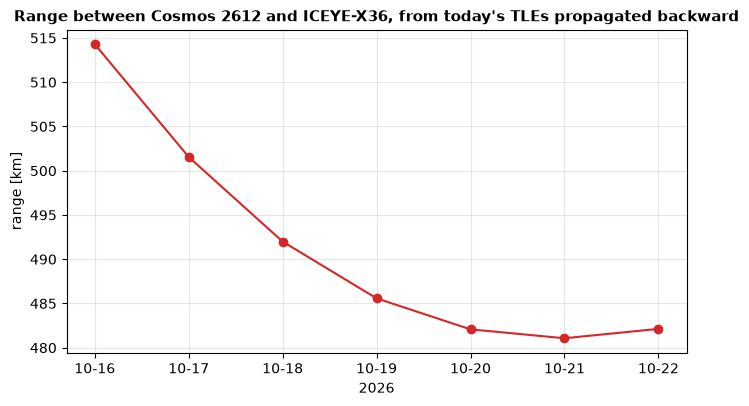

range by date [km]: [514.3 501.5 492.  485.6 482.1 481.1 482.1]


In [4]:
dates = [(2026, 10, d) for d in range(16, 23)]
ranges_km = []
for y, m, d in dates:
    jd, fr = jday(y, m, d, 0, 0, 0)
    c, dep = state_at(sat_iceye, jd, fr), state_at(sat_cosmos, jd, fr)
    ranges_km.append(np.linalg.norm(inertial_to_lvlh(c, dep)[:3]))

labels = [f"10-{d:02d}" for _, _, d in dates]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(labels, ranges_km, color=COL_NUM, marker="o")
ax.set_xlabel("2026"); ax.set_ylabel("range [km]")
ax.set_title("Range between Cosmos 2612 and ICEYE-X36, from today's TLEs propagated backward")
plt.show()

print("range by date [km]:", np.round(ranges_km, 1))

## What the CW decomposition adds, and its limit here

`relative_orbit_from_state`, the same tool used throughout this project to read a relative state as an ellipse size, phase, and drift instead of six raw numbers, applied to today's relative state. At a separation of tens of kilometres this is well outside the small-separation regime the linearization assumes, the same regime this project's own nonlinear-vs-linear comparisons (`cw_fundamentals.ipynb`) showed breaking down well before this scale, so the numbers below are a rough characterization of the drift, not a precise design-grade description the way they are for this project's own few-hundred-metre missions.

In [5]:
n_iceye = sat_iceye.no_kozai / 60.0  # rad/min -> rad/s
orbit = relative_orbit_from_state(rel, n_iceye)

print(f"x_off = {orbit.x_off/1e3:.2f} km   (nonzero: real, ongoing along-track drift, not a held formation)")
print(f"rho   = {orbit.rho/1e3:.2f} km")
print(f"rho_z = {orbit.rho_z:.1f} m   (small: consistent with the near-identical orbital planes)")
print(f"drift rate = {orbit.drift_rate(n_iceye)*1e3:.2f} mm/s "
      f"= {orbit.drift_rate(n_iceye) * 2*np.pi/n_iceye / 1e3:.2f} km per orbit")

x_off = -68.22 km   (nonzero: real, ongoing along-track drift, not a held formation)
rho   = 51.79 km
rho_z = 163.1 m   (small: consistent with the near-identical orbital planes)
drift rate = 112213.28 mm/s = 642.99 km per orbit


That 643 km per orbit is not a real prediction, it is what happens when a formula built for hundred-metre separations is pushed to 68 km: the actual range history plotted above closed by about 33 km over 6 days, roughly 5.5 km per day, more than three orders of magnitude slower than the linear model's extrapolation. This is the same breakdown `cw_fundamentals.ipynb` already showed happening gradually as separation grows; here it is simply far enough past that point that the mismatch is impossible to miss, which is itself a useful, concrete illustration of where this project's linear tools stop being trustworthy, rather than an abstract caveat.

A nonzero, sizeable $x_{off}$ says the two satellites currently have meaningfully different semi-major axes, so the along-track separation is still actively growing, not holding at a fixed offset the way this project's own 2:1 safety ellipse is designed to. That is consistent with a satellite that closed in deliberately for a specific pass rather than one settling into a maintained co-orbit, though confirming that reading properly needs the actual pre- and post-encounter elements, not today's.

## Summary

Public TLE data, the project's own `sgp4`-free tools exactly as built for its own missions, reconstructs a real encounter's geometry well enough to find a signature, the matched orbital planes and the small cross-track offset, that is hard to explain as coincidence, even without data from the actual close-approach dates. What it could not do yet is reproduce the specific reported distances, because CelesTrak only serves current elements, and the mean elements fitted today do not carry precise information about where these satellites were six days and, in Cosmos 2612's case, several maneuvers ago.

The next step, if it is worth taking, is historical TLEs bracketing 15 to 19 October, most plausibly from a free Space-Track account, which would let this notebook do two more things this one could not: actually validate against the reported 500 m to 3 km figures using contemporaneous elements, and estimate the maneuvers themselves by comparing orbital elements immediately before and after each reported shift, the same way analysts infer delta-v from TLE histories in practice.